# Zero-Shot Classification, Linear Probing, and Segmentation with MedSigLIP
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/f10409/MedGemma_demo/blob/main/2_medsiglip_demo.ipynb)

**MedSigLIP** is a model with an image encoder and a text encoder. MedGemma uses the same image encoder to read images. Google also gives MedSigLIP as a separate model.
- The **image encoder** changes an image into an **embedding**: a list of 1,152 numbers that describes the image.
- The **text encoder** changes a text into an embedding of the same size.

Similar images and texts get similar embeddings. For example, a CXR with cardiomegaly and the text "cardiomegaly" get similar embeddings.

In notebook 1, MedGemma writes text. Here we use only the embeddings, for three tasks:
1. **Zero-shot classification:** compare the image embedding with the text embedding of each class name. No training.
2. **Linear probing:** train a small model on the image embeddings with labeled images. MedSigLIP does not change.
3. **Segmentation:** train a small model on the embeddings of small image squares (patches) to find the lungs.

We use the **evaluators** of [RadHarmony](https://f10409.github.io/RadHarmony/). An evaluator does one task in one function call. It gives a table of scores in the same format for each task.

Links: [Model card](https://huggingface.co/google/medsiglip-448) · [Developer site](https://developers.google.com/health-ai-developer-foundations/medsiglip) · [MedGemma paper (with MedSigLIP)](https://arxiv.org/abs/2507.05201)

<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/medsiglip_overview.png" alt="overview" width="600">

## Step 1: Select a GPU and Download the Data
1. Select a GPU: **Runtime → Change runtime type → T4 GPU**. Do this before you run any cell. If you change the runtime later, Colab deletes the downloaded data.
2. Run the next cell. It gets the helper code from GitHub. Then it downloads two free datasets from the U.S. National Library of Medicine:
   - **Open-i** chest X-rays from Indiana University, with labels from the reports ([source](https://openi.nlm.nih.gov/faq)). We use it for classification. About 1.4 GB.
   - **Montgomery County** chest X-rays: 138 images with lung masks, made under the supervision of a radiologist ([source](https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/Montgomery-County-CXR-Set/MontgomerySet/index.html)). We use it for segmentation. About 0.6 GB.

The download takes a few minutes. While it runs, do Step 2. If the data is already there, the cell skips the download.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

# ---- 1. Get the helper code (utils/) from GitHub (Colab only)
if IN_COLAB:
    if not os.path.exists("/content/MedGemma_demo"):
        !git clone -q https://github.com/f10409/MedGemma_demo.git /content/MedGemma_demo
    %cd /content/MedGemma_demo

# ---- 2. Download Open-i (classification) and Montgomery (segmentation)
from utils.montgomery_data import download_montgomery
from utils.openi_data import download_openi

DATA_DIR = download_openi("data/OpenI-IU-CXR")
MONTGOMERY_DIR = download_montgomery("data/Montgomery-CXR")

✅ Open-i data ready: data/OpenI-IU-CXR
✅ Montgomery data ready: data/Montgomery-CXR/MontgomerySet/CXR_png


## Step 2: Get Access to MedSigLIP
You need permission to download MedSigLIP. Do these 4 parts on the Hugging Face website and in Colab. You do them only once.

**Did you do notebook 1?** Then you have a token already. Do only parts 1 and 4: accept the MedSigLIP terms, and turn on **Notebook access** for `HF_TOKEN` in this notebook.

1. Log in to Hugging Face (or sign up). Open the [MedSigLIP page](https://huggingface.co/google/medsiglip-448) and accept the terms.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_login.png" alt="login" width="750"><br>
2. Open your [token settings](https://huggingface.co/settings/tokens). Create a token of type **Read**.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_access0.png" alt="access0" width="750"><br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_access1.png" alt="access1" width="750"><br>
3. Copy the token.<br>
<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/HF_token.png" alt="token" width="500"><br>
4. Save the token in Colab:
   - In the left sidebar, click the 🔑 **Secrets** icon.
   - Click **Add new secret**. Name: `HF_TOKEN`. Value: your token. (Skip this if you have it already.)
   - Turn on **Notebook access**.

   Not on Colab? Skip part 4. Run `hf auth login` in a terminal, or run `from huggingface_hub import login; login()` in a new cell.

## Step 3: Setup
When the download in Step 1 is done and you finish Step 2, run the next cell. It installs the packages and imports the libraries. Then it checks the GPU, your Hugging Face token, and your access to MedSigLIP. If Colab asks for access to `HF_TOKEN`, click **Grant access**.

If a check fails, the error message tells you what to do. Fix it, then run the cell again.

> pip may show "ERROR: pip's dependency resolver ..." with a list of packages. This is only a warning. You can ignore it.

In [2]:
# ---- 1. Install RadHarmony and the other packages (Colab only)
if IN_COLAB:
    # --no-deps keeps the Colab packages unchanged,
    # so we install only the RadHarmony packages that we need.
    !pip install -q --no-deps git+https://github.com/f10409/RadHarmony.git
    !pip install -q "monai<1.6" pydicom "transformers>=4.56"

# ---- 2. Import the libraries
import shutil
import warnings

import pandas as pd
import torch
import torch.nn.functional as F

# Datasets
from radharmony.dataset import MontgomeryCXRDataset, OpenICXRDataset
from radharmony.harmonizer.openi_cxr import OpenICXRHarmonizer

# MedSigLIP and the evaluators
from radharmony.evaluator import (
    LinearProbeEvaluator,
    LinearProbeSegEvaluator,
    ZeroShotEvaluator,
)
from radharmony.evaluator.backbones import make_medsiglip

# Utilities
from utils.hf_token import check_hf_token, check_model_access
from utils.openi_data import select_cohort
from utils.segmentation import show_seg_predictions
from utils.zero_shot import show_similarity

# ---- 3. Check the GPU
assert torch.cuda.is_available(), "No GPU found. In Colab: Runtime → Change runtime type → T4 GPU."
print(f"GPU: {torch.cuda.get_device_name(0)}")
DEVICE = "cuda"
# A T4 GPU has no fast bfloat16, so we use float16 there. Both give almost the same results.
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
NUM_WORKERS = min(4, os.cpu_count())  # Processes that load the images
CACHE_DIR = "cache"  # Saved embeddings, masks, and predictions

# ---- 4. Check the Hugging Face token and the access to MedSigLIP
check_hf_token(IN_COLAB)
check_model_access("google/medsiglip-448")

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
✅ Hugging Face token found
✅ You have access to google/medsiglip-448


## Step 4: Load MedSigLIP
RadHarmony has a function for each model: `make_medsiglip` loads MedSigLIP. It gives 4 objects:
- `transform`: prepares an image for the model. It changes the image to RGB, resizes it to 448 × 448 pixels, and scales the pixel values. We give it to the dataset.
- `encoder`: the image encoder. Input: images. Output: one embedding (1,152 numbers) for each image.
- `text_encoder`: the text encoder. Input: tokens (text changed into numbers). Output: one embedding for each text.
- `processor`: changes text into tokens for the text encoder.

`output_keys={"img", "cls"}` tells the transform to keep the image and the class labels.

In [3]:
# Load only once: each copy of the model uses 3.5 GB of GPU memory
if "encoder" not in globals():
    transform, encoder, text_encoder, processor = make_medsiglip(
        device=DEVICE, output_keys={"img", "cls"}, dtype=DTYPE
    )
print("✅ MedSigLIP loaded")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


✅ MedSigLIP loaded


## Step 5: Data Preparation
We use the same Open-i data as notebook 1. The next cell:
1. Reads the reports with RadHarmony and makes a table. Each row is one image, with its view, report, and labels.
2. Selects up to 100 frontal images for each class (No Finding, Atelectasis, Cardiomegaly, Consolidation, and Pleural Effusion), as in notebook 1. We use only images with exactly one label. Consolidation (57) and Pleural Effusion (33) have fewer images, so we get 390 images.
3. Makes a RadHarmony dataset. Now each sample is the image after the MedSigLIP `transform`, and its labels.

The dataset has 8 labels. `LABELS` are the 4 conditions that we classify, as in notebook 1. RadHarmony writes them in lowercase, with `_` in place of spaces.

In [4]:
# ---- 1. Harmonize with RadHarmony
harmonizer = OpenICXRHarmonizer(base_dir=DATA_DIR)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # We did not download the DICOM files, so DICOM warnings are expected
    df_all = harmonizer.harmonize()

# ---- 2. Select a balanced sample
meta = select_cohort(df_all, n_per_class=100, seed=5656)
print("Images per class in the sample:")
display(meta.Pathology.value_counts())

# ---- 3. Make the RadHarmony dataset, with the MedSigLIP transform
dataset = OpenICXRDataset(
    base_image_dir=DATA_DIR,
    harmonized_df=meta,
    transform=transform,
    output_cls=True,
    cache_dir=None,
)
samples = dataset.get_datasets()  # The samples, in the same order as meta
LABELS = ["atelectasis", "cardiomegaly", "consolidation", "pleural_effusion"]

sample = samples[0]
print(f"Image: {tuple(sample['img'].shape)} (color channels × height × width)")
print("Labels:", dict(zip(dataset.LABEL_COLS, sample["cls"].tolist())))

Images per class in the sample:


Pathology
No Finding          100
Atelectasis         100
Cardiomegaly        100
Consolidation        57
Pleural Effusion     33
Name: count, dtype: int64

Image: (3, 448, 448) (color channels × height × width)
Labels: {'atelectasis': 0.0, 'cardiomegaly': 0.0, 'consolidation': 0.0, 'edema': 0.0, 'no_finding': 1.0, 'pleural_effusion': 0.0, 'pneumothorax': 0.0, 'support_devices': 0.0}


## Step 6: Zero-Shot Classification
In zero-shot classification, we compare the image embedding with the text embedding of each class. The class with the most similar text is the answer. We do not train the model, and we give it no examples.

<img src="https://raw.githubusercontent.com/f10409/MedGemma_demo/main/notebook_figs/zero_shot_classification.png" alt="zero-shot classification" width="700">

We measure the similarity with the **cosine similarity**. A higher value means that the image and the text are more similar. For MedSigLIP, the values are small (about −0.3 to 0.4). Only their order is important.

### Zero-Shot Example
The next cell does zero-shot classification for one image "by hand":
1. Gets the image embedding with `encoder`.
2. Gets one text embedding for each class name with `processor` and `text_encoder`.
3. Calculates the cosine similarity between the image and each text.
4. Shows the similarities. The highest one (red) is the answer.

Change `index` to try other images, or change the `prompts`.

Image embedding: (1, 1152) (1 image × 1,152 numbers)
Text embeddings: (5, 1152) (5 prompts × 1,152 numbers)


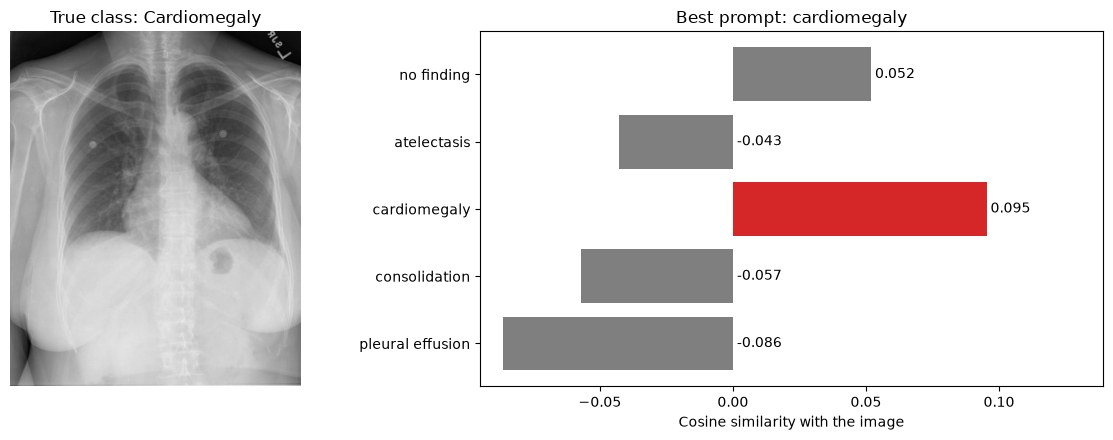

In [5]:
index = 12  # you can select other sample (0 to 389)
prompts = ["no finding", "atelectasis", "cardiomegaly", "consolidation", "pleural effusion"]

# ---- 1. Image embedding
image = samples[index]["img"][None].to(DEVICE)  # [None] makes a batch of 1 image
with torch.no_grad(), torch.autocast("cuda", dtype=DTYPE):
    image_embedding = encoder(image).float().cpu()
print(f"Image embedding: {tuple(image_embedding.shape)} (1 image × 1,152 numbers)")

# ---- 2. Text embeddings
tokens = processor(text=prompts, padding="max_length", truncation=True, return_tensors="pt")  # Max. 64 tokens
text_embeddings = text_encoder(tokens)
print(f"Text embeddings: {tuple(text_embeddings.shape)} ({len(prompts)} prompts × 1,152 numbers)")

# ---- 3. Cosine similarity of the image with each prompt
similarity = F.normalize(image_embedding, dim=-1) @ F.normalize(text_embeddings, dim=-1).T

# ---- 4. Show the result
image_path = os.path.join(DATA_DIR, meta.image_path[index])
show_similarity(image_path, prompts, similarity[0], true_class=meta.Pathology[index])

### Evaluate Zero-Shot Classification
Now we use all 390 images with `ZeroShotEvaluator`. Here we do not pick one class. Each condition gets its own score, as in a yes/no test. For each condition, the evaluator:
1. Gets the embeddings of all images. It saves them in `embedding_cache`, so the next run is fast.
2. Gets the text embedding of the prompt, for example "pleural effusion".
3. Gives each image a score: its cosine similarity with the prompt.
4. Calculates the **AUROC** from the scores and the labels.

**AUROC** is the area under the ROC curve, as in diagnostic accuracy studies. 1.0 is perfect, and 0.5 is chance. AUROC needs no threshold, so we can use it for zero-shot scores. The table also shows the **macro average** (the mean of the 4 conditions).

In [6]:
# One prompt for each condition (you can give more than one; the evaluator uses their mean)
PROMPTS = {
    "atelectasis": ["atelectasis"],
    "cardiomegaly": ["cardiomegaly"],
    "consolidation": ["consolidation"],
    "pleural_effusion": ["pleural effusion"],
}
EMBEDDING_CACHE = f"{CACHE_DIR}/medsiglip_openi_{len(meta)}images"

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # Warns that F1 needs a threshold. Zero-shot has none, so we use AUROC.
    zero_shot = ZeroShotEvaluator(
        image_encoder=encoder,
        text_encoder=text_encoder,
        tokenizer=processor,
        dataset=dataset,
        labels=LABELS,
        prompts=PROMPTS,
        embedding_cache=EMBEDDING_CACHE,
        autocast_dtype=DTYPE,
        num_workers=NUM_WORKERS,
    )
    results_zero_shot = zero_shot.evaluate()

display(results_zero_shot[["label", "auroc"]].round(3))

,label,auroc
0,atelectasis,0.794
1,cardiomegaly,0.909
2,consolidation,0.817
3,pleural_effusion,0.834
4,macro_average,0.839


### Try Your Own Prompts
The prompts are the only thing that you can change in zero-shot classification. Small changes in the words can change the AUROC. Try, for example:
- Longer prompts: "a chest x-ray with pleural effusion".
- Other words: "enlarged heart" for cardiomegaly.
- More prompts for one condition: `["pleural effusion", "fluid in the pleural space"]`.
- **Negative prompts:** the score is then the similarity with the prompt minus the similarity with the negative prompt. For example: `{"cardiomegaly": ["normal heart size"]}`.

The embeddings come from the cache, so this cell is fast.

In [7]:
my_prompts = {
    "atelectasis": ["a chest x-ray with atelectasis"],
    "cardiomegaly": ["a chest x-ray with cardiomegaly"],
    "consolidation": ["a chest x-ray with consolidation"],
    "pleural_effusion": ["a chest x-ray with pleural effusion"],
}
my_negative_prompts = None  # For example: {label: ["a normal chest x-ray"] for label in LABELS}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    my_zero_shot = ZeroShotEvaluator(
        image_encoder=encoder,
        text_encoder=text_encoder,
        tokenizer=processor,
        dataset=dataset,
        labels=LABELS,
        prompts=my_prompts,
        negative_prompts=my_negative_prompts,
        embedding_cache=EMBEDDING_CACHE,
        autocast_dtype=DTYPE,
        num_workers=NUM_WORKERS,
    )
    my_results = my_zero_shot.evaluate()

display(
    pd.DataFrame(
        {
            "PROMPTS": results_zero_shot.set_index("label")["auroc"],
            "my_prompts": my_results.set_index("label")["auroc"],
        }
    ).round(3)
)

,PROMPTS,my_prompts
label,,
atelectasis,0.794,0.738
cardiomegaly,0.909,0.888
consolidation,0.817,0.815
pleural_effusion,0.834,0.797
macro_average,0.839,0.810


## Step 7: Linear Probing
Zero-shot classification uses no labels. If we have labeled images, we can do better: we train a small model on the image embeddings. This is a **linear probe**:
- We **freeze** MedSigLIP: it does not change. We use it only to get the embeddings.
- For each condition, we train a **logistic regression** (a simple linear model). Input: the embedding of an image. Output: the probability of the condition.

Training is fast (seconds), because the embeddings come from the cache.

To test the model on images that it did not see in training, `LinearProbeEvaluator` uses **5-fold cross-validation**:
1. It divides the images into 5 groups (**folds**). Images of one patient stay in the same fold.
2. It trains on 4 folds and tests on the remaining fold.
3. It does this 5 times, so each fold is the test fold one time.

The evaluator also keeps 10% of the training images aside to pick the threshold for F1. So the model trains on about 280 images in each fold.

The next cell runs the linear probe. Then it compares the mean AUROC of the 5 test folds with the zero-shot AUROC.

In [8]:
linear_probe = LinearProbeEvaluator(
    image_encoder=encoder,
    dataset=dataset,
    labels=LABELS,
    n_folds=5,
    embedding_cache=f"{EMBEDDING_CACHE}.test.pkl",  # The embeddings that the zero-shot evaluator saved
    autocast_dtype=DTYPE,
    num_workers=NUM_WORKERS,
)
results_linear_probe = linear_probe.evaluate()  # One row for each fold and each label

# Compare zero-shot and linear probing (AUROC)
comparison = pd.DataFrame(
    {
        "Zero-shot": results_zero_shot.set_index("label")["auroc"],
        "Linear probe": results_linear_probe.groupby("label")["auroc"].mean(),
    }
)
display(comparison.loc[[*LABELS, "macro_average"]].round(3))

,Zero-shot,Linear probe
label,,
atelectasis,0.794,0.869
cardiomegaly,0.909,0.918
consolidation,0.817,0.829
pleural_effusion,0.834,0.846
macro_average,0.839,0.865


### How Many Labeled Images Do We Need?
Labels are expensive, because a radiologist must make them. With `n_train_samples`, the evaluator uses only some of the training images of each fold, for example 20, 50, or 100. `-1` (column "all") means all training images (about 310). Again, 10% of these images only pick the threshold.

Compare the results with the zero-shot macro AUROC above. In our run, zero-shot classification (0.839) was better than the linear probe with 20 or 50 labeled images (0.717 and 0.827).

The "all" column can be a little different from Step 7 (for example 0.859 and 0.865). The 10% that each run keeps aside is a different random selection, so small differences are normal.

In [9]:
learning_curve = LinearProbeEvaluator(
    image_encoder=encoder,
    dataset=dataset,
    labels=LABELS,
    n_folds=5,
    n_train_samples=[20, 50, 100, -1],
    embedding_cache=f"{EMBEDDING_CACHE}.test.pkl",
    autocast_dtype=DTYPE,
    num_workers=NUM_WORKERS,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # With 20 images, some conditions have no positive image
    results_curve = learning_curve.evaluate()

# Mean AUROC of the 5 folds. Columns: the number of training images
curve = results_curve.groupby(["label", "n_train"])["auroc"].mean().unstack()
curve = curve.loc[[*LABELS, "macro_average"], [20, 50, 100, -1]].rename(columns={-1: "all"})
display(curve.round(3))

n_train,20,50,100,all
label,,,,
atelectasis,0.687,0.827,0.836,0.864
cardiomegaly,0.816,0.881,0.897,0.910
consolidation,0.682,0.767,0.816,0.839
pleural_effusion,0.703,0.834,0.819,0.822
macro_average,0.717,0.827,0.842,0.859


## Step 8: Segmentation
In segmentation, the model labels each pixel: lung or not lung.

MedSigLIP divides the image into a grid of 32 × 32 small parts (patches). Each patch is 14 × 14 pixels, and each patch gets its own embedding. In **segmentation mode** (`output_keys={"img", "mask"}`), the encoder gives these patch embeddings, not one embedding for the full image.

`LinearProbeSegEvaluator` trains a **head**: a small model on top of the frozen encoder. Here the head is linear, as in Step 7. For each patch, it calculates the probability of lung. Then it enlarges the result to the size of the model input (448 × 448 pixels). MedSigLIP is frozen again.

We use the **Montgomery** dataset: 138 CXRs with left and right lung masks. RadHarmony puts the two masks together into one lung mask. We use **3-fold cross-validation** and 10 training epochs (passes through the training images), so that it runs in a few minutes on a T4.

**Score: Dice**, the overlap between the predicted mask and the true mask. 1.0 is a perfect overlap, and 0.0 is no overlap. The table also shows the **IoU** (intersection over union), a similar overlap score.

The next cell:
1. Loads MedSigLIP again, in segmentation mode.
2. Makes the Montgomery dataset. The first run saves the prepared images and masks in the cache.
3. Trains and tests the head on each fold. It saves the predicted masks.

In [10]:
# ---- 1. MedSigLIP in segmentation mode: one embedding for each of the 32 × 32 patches
if "seg_encoder" not in globals():  # Load only once (3.5 GB of GPU memory)
    seg_transform, seg_encoder, _, _ = make_medsiglip(
        device=DEVICE, output_keys={"img", "mask"}, dtype=DTYPE
    )

# ---- 2. Montgomery dataset with lung masks
seg_dataset = MontgomeryCXRDataset(
    base_image_dir=MONTGOMERY_DIR,
    transform=seg_transform,
    output_mask=True,
    mask_output_dir=f"{CACHE_DIR}/montgomery_lung_masks",  # Left + right lung mask, one file per image
    cache_dir=f"{CACHE_DIR}/montgomery_medsiglip",  # Prepared images, so each epoch is fast
)

# ---- 3. Train and test the head (3 folds)
SEG_OUTPUT_DIR = f"{CACHE_DIR}/segmentation"
shutil.rmtree(SEG_OUTPUT_DIR, ignore_errors=True)  # Delete the predicted masks of an old run
segmentation = LinearProbeSegEvaluator(
    image_encoder=seg_encoder,
    dataset=seg_dataset,
    num_classes=2,  # Background and lung
    n_folds=3,
    epochs=10,
    batch_size=8,
    autocast_dtype=DTYPE,
    num_workers=NUM_WORKERS,
    save_predictions=True,  # Save the predicted masks, so we can show them
    output_dir=SEG_OUTPUT_DIR,
)
results_seg = segmentation.evaluate()

# Lung Dice and IoU for each test fold (class_1 is the lung)
display(results_seg[results_seg.label == "class_1"].groupby("fold")[["dice", "iou"]].mean().round(3))
print(f"Mean lung Dice: {results_seg.loc[results_seg.label == 'class_1', 'dice'].mean():.3f}")

Fusing lung masks: 100%|██████████| 138/138 [00:00<00:00, 49636.73it/s]


,dice,iou
fold,,
0,0.899,0.817
1,0.892,0.808
2,0.906,0.829


Mean lung Dice: 0.899


### Show the Predicted Masks
The next cell shows 3 images of the first test fold. The model did not see these images in training. Columns: the image, the true lung mask (the reference mask from the dataset), and the predicted lung mask.

The predicted mask has rough edges and some small holes, because each patch is 14 × 14 pixels, and the head is linear. A larger head can give smoother edges, for example `ConvProbeSegEvaluator` or `UPerNetSegEvaluator` in RadHarmony.

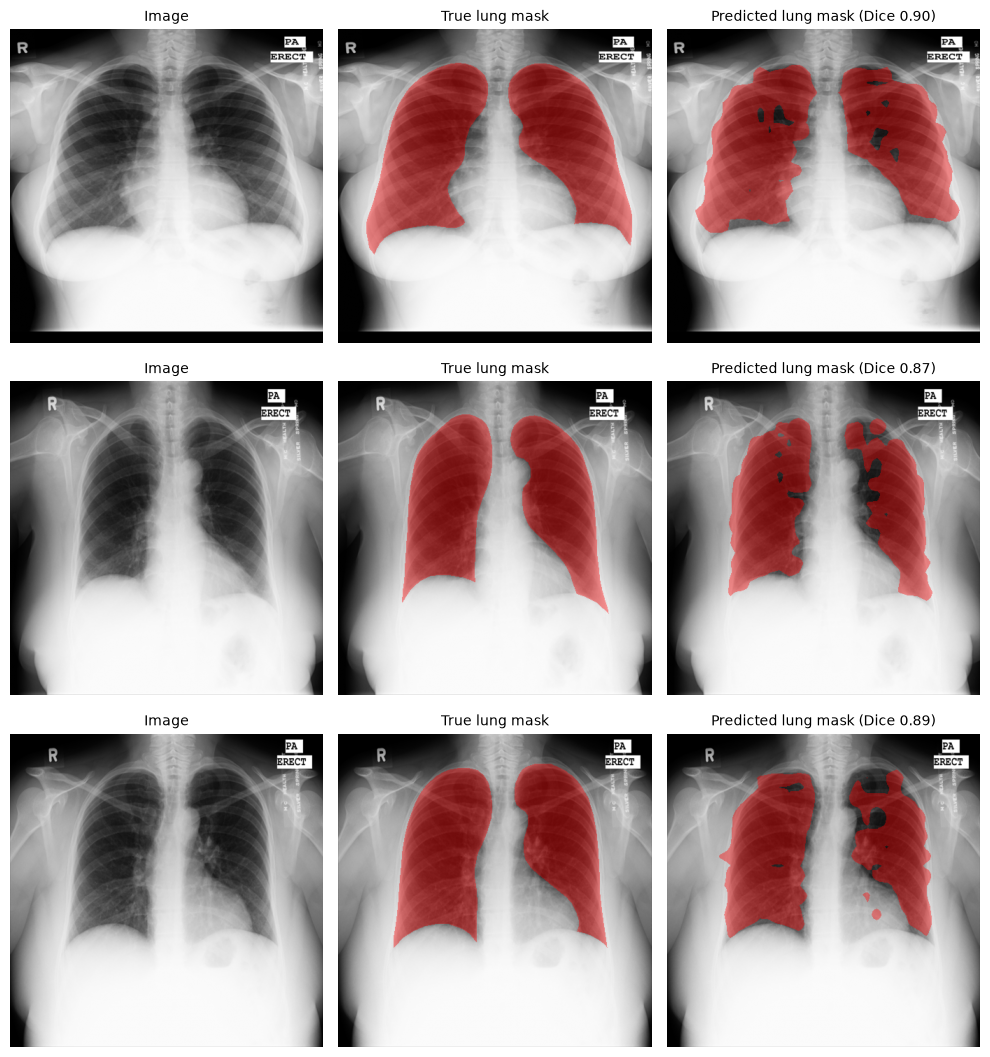

In [11]:
show_seg_predictions(SEG_OUTPUT_DIR, MONTGOMERY_DIR, fold=0, n=3)

## Step 9: Summary
In this notebook, you used MedSigLIP (the image encoder of MedGemma, and a text encoder) for three tasks. Each task was one RadHarmony evaluator call, and each gave a table of scores.

| Task | Evaluator | Labels needed? | Training | Score |
|---|---|---|---|---|
| Zero-shot classification | `ZeroShotEvaluator` | No (only for the score) | None | AUROC |
| Linear probing | `LinearProbeEvaluator` | Yes | Logistic regression on the embeddings (seconds) | AUROC |
| Segmentation | `LinearProbeSegEvaluator` | Yes (masks) | Linear head on the patch embeddings (minutes) | Dice |

**Zero-shot prompting (notebook 1) or zero-shot classification (this notebook)?**
- **Prompting** with MedGemma gives text. You can ask any question, and the model can explain its answer. But it is slow, and you must read the answer from the text.
- **Classification** with MedSigLIP gives a score for each class. It is fast, it needs a small GPU, and the output always has the same format. You can also use the score for an ROC curve.

**Learn more:**
- RadHarmony has other evaluators with the same interface: k-nearest neighbors (`KNNProbeEvaluator`), fine-tuning (`FinetuneEvaluator`), and larger segmentation heads (`ConvProbeSegEvaluator`, `UPerNetSegEvaluator`). See the [RadHarmony docs](https://f10409.github.io/RadHarmony/).
- RadHarmony also has recipes for other encoders, for example RAD-DINO (`make_raddino`) and BiomedCLIP (`make_biomed_clip`). The evaluator calls stay the same, so you can compare encoders.
- The [MedSigLIP demo](https://github.com/f10409/MedSigLIP_demo) shows zero-shot classification and fine-tuning with the Hugging Face model directly.

> ⚠️ These models are for research and education only. Do not use them for patient care.